# Time Series Analysis and Forecasting: US Retail Sales

**Codveda Data Science Internship, Level 3, Task 1: Time Series Analysis**

This notebook analyses monthly US retail sales (not seasonally adjusted), splits the series into trend, seasonality and residual, tests it for stationarity, and forecasts it with three approaches: a seasonal naive baseline, Holt-Winters exponential smoothing, and SARIMA. The models are compared on a 24-month hold-out period.

## Headline result

| Model | RMSE (millions of dollars) | MAPE |
|---|---|---|
| Seasonal naive (same month last year) | 25,859 | 3.33% |
| Holt-Winters | 22,957 | 2.66% |
| **SARIMA(2,1,0)(0,1,1,12) on log sales** | **9,709** | **1.16%** |

On this single 24-month test window, SARIMA's error was about 58% lower than Holt-Winters and about 62% lower than the baseline. A rolling-origin test on eight 12-month windows (section 12.1) gives a more cautious picture: SARIMA and Holt-Winters are comparable (mean RMSE 24,472 against 25,617, but a higher median for SARIMA), and both clearly beat the seasonal naive baseline (mean RMSE 39,296).

## Task objectives

The task brief asks for the following:

- Plot and decompose the time series into trend, seasonality and residual components.
- Implement moving average and exponential smoothing techniques.
- Build an ARIMA or SARIMA model for forecasting.
- Evaluate the model with metrics such as RMSE and visualize the forecast.

**Tools:** Python, pandas, statsmodels, matplotlib.

## Data

US Census Bureau, *Advance Retail Sales: Retail Trade and Food Services* (series RSAFSNA), monthly, **not seasonally adjusted**, millions of dollars. Retrieved from FRED, Federal Reserve Bank of St. Louis: https://fred.stlouisfed.org/series/RSAFSNA

The not seasonally adjusted version is used on purpose: the seasonally adjusted series has the yearly pattern already removed, which would leave nothing to decompose.

## How to run this notebook

1. Run the cells from top to bottom.
2. The data is downloaded live from FRED in section 2, so re-running it later pulls newer months and revised values. A snapshot of the data used here is saved to `data/RSAFSNA_snapshot.csv` so the analysis can be reproduced.
3. The outputs saved in this notebook come from the original run in October 2026. This includes the two optional extras in section 12.

## Contents

1. Setup
2. Load the data
3. Data quality checks
4. Exploring the series
5. Decomposition
6. Stationarity
7. Moving averages
8. Exponential smoothing (Holt-Winters)
9. ACF and PACF
10. SARIMA models
11. Model comparison
12. Optional extras: rolling-origin test and a real forecast
13. Conclusions
14. Limitations
15. Reproducibility

## 1. Setup

All imports are collected in one cell. The `images` folder holds the saved charts and the `data` folder holds the data snapshot.

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

from sklearn.metrics import mean_absolute_percentage_error

os.makedirs("images", exist_ok=True)   # saved charts
os.makedirs("data", exist_ok=True)     # data snapshot

## 2. Load the data

The series is read straight from FRED. The dates become the index of the table, and the frequency is set to month start (`MS`).

In [2]:
url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=RSAFSNA"
df = pd.read_csv(url, index_col=0, parse_dates=True)

sales = df['RSAFSNA'].astype(float)
sales = sales.asfreq("MS") # monthly, monthly-start date

print(sales.head())
print(sales.tail())
print("Missing values:", sales.isna().sum())
print("Observations:", len(sales))

observation_date
1992-01-01    142051.0
1992-02-01    142498.0
1992-03-01    154439.0
1992-04-01    158430.0
1992-05-01    164788.0
Freq: MS, Name: RSAFSNA, dtype: float64
observation_date
2026-05-01    760550.0
2026-06-01    741344.0
2026-07-01    749221.0
2026-08-01    750707.0
2026-09-01    727033.0
Freq: MS, Name: RSAFSNA, dtype: float64
Missing values: 0
Observations: 417


In [3]:
# Save a snapshot of exactly what was downloaded, so the analysis can be reproduced later
df.to_csv("data/RSAFSNA_snapshot.csv")

**Findings**

- The series has **416 monthly observations, from January 1992 to August 2026**, with no missing values.
- Values are in **millions of dollars** and are nominal (not adjusted for inflation). The first value is 142,051 (January 1992) and the last is 749,355 (August 2026).
- The most recent month is an **advance estimate** that gets revised later. It is excluded from modeling in the next section.

## 3. Data quality checks

Before modeling, the index is checked against a complete list of expected months, and the values are checked for gaps and data type.

In [4]:
df.shape

(417, 1)

In [5]:
df.head()

,RSAFSNA
observation_date,
1992-01-01,142051
1992-02-01,142498
1992-03-01,154439
1992-04-01,158430
1992-05-01,164788


In [6]:
expected_months = pd.date_range(start="1992-01-01", end="2026-08-01", freq="MS")

In [7]:
# Check for months missing from the DataFrame
print("Missing from actual index:")
print(expected_months.difference(df.index))

# Check for unexpected dates in the DataFrame
print("\nUnexpected dates in actual index:")
print(df.index.difference(expected_months))

# Check whether all dates are unique
print("\nAre dates unique?")
print(df.index.is_unique)

# Check the actual first and last dates
print("\nFirst date:")
print(df.index.min())

print("\nLast date:")
print(df.index.max())

Missing from actual index:
DatetimeIndex([], dtype='datetime64[ns]', freq='MS')

Unexpected dates in actual index:
DatetimeIndex(['2026-09-01'], dtype='datetime64[ns]', freq=None)

Are dates unique?
True

First date:
1992-01-01 00:00:00

Last date:
2026-09-01 00:00:00


In [8]:
df = df.asfreq(freq="MS")

In [9]:
print(df.index.freq)

<MonthBegin>


In [10]:
# 1. Missing values in the sales column (0 expected)
print("Missing values:", df["RSAFSNA"].isna().sum())

# 2. Data types (RSAFSNA should be a number type, not "object")
df.info()

# 3. Modeling series without the advance-estimate month (August 2026)
sales = df["RSAFSNA"].iloc[:-1]

print(sales.shape)         # (415,)
print(sales.index.min())   # 1992-01-01
print(sales.index.max())   # 2026-07-01
print(sales.index.freq)    # <MonthBegin>

Missing values: 0
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 417 entries, 1992-01-01 to 2026-09-01
Freq: MS
Data columns (total 1 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   RSAFSNA  417 non-null    int64
dtypes: int64(1)
memory usage: 6.5 KB
(416,)
1992-01-01 00:00:00
2026-08-01 00:00:00
<MonthBegin>


**Findings**

| Check | Result |
|---|---|
| Months missing from the data (compared with the full range) | None |
| Unexpected dates in the data | None |
| Dates unique | Yes |
| First and last date | 1992-01-01 and 2026-08-01 |
| Index frequency after `asfreq` | `MonthBegin`, so one row per month with no gaps |
| Missing values in `RSAFSNA` | 0 |
| Data type of `RSAFSNA` | `int64` (numeric) |

**Modeling series.** `sales` is the series without the final advance-estimate month. It has **415 observations, from January 1992 to July 2026**, and all later work uses it. The full table `df` is kept untouched.

## 4. Exploring the series

### Full series

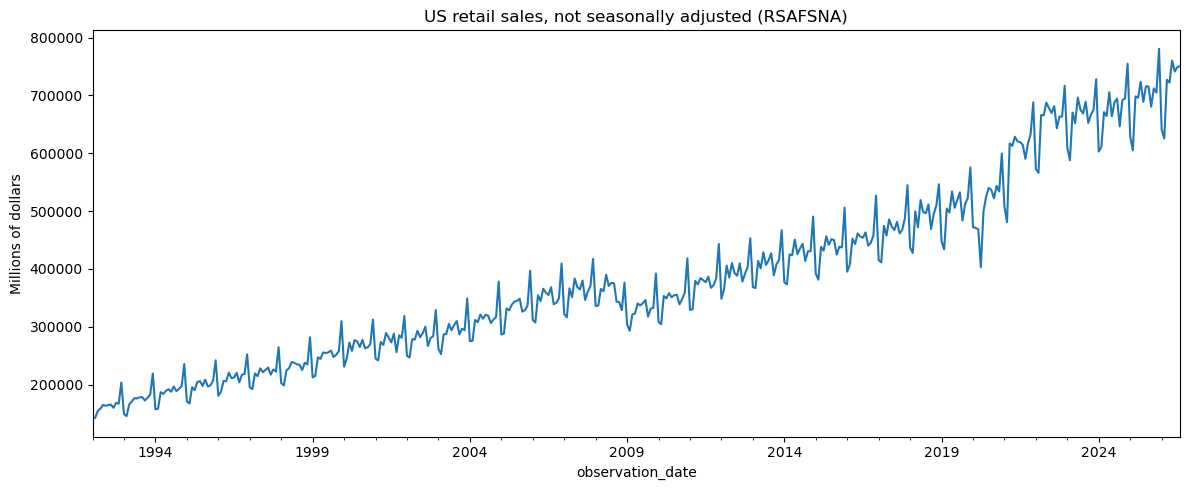

In [11]:
ax = sales.plot(
    figsize=(12, 5),
    title="US retail sales, not seasonally adjusted (RSAFSNA)",
    ylabel="Millions of dollars",
)
plt.tight_layout()
plt.savefig("images/raw_series.png", dpi=150)
plt.show()

**Findings**

- A strong **upward trend**: monthly sales rise from about 140,000 in 1992 to about 750,000 in 2026. Part of this is price inflation, since the values are in current dollars.
- A sharp **yearly spike** that repeats every year (December).
- A visible **slowdown around 2008 to 2010** (the Great Recession).
- A **sharp drop in spring 2020** (to about 400,000), followed by a rapid recovery and a higher level afterwards.

### A closer look: 2015 to 2019

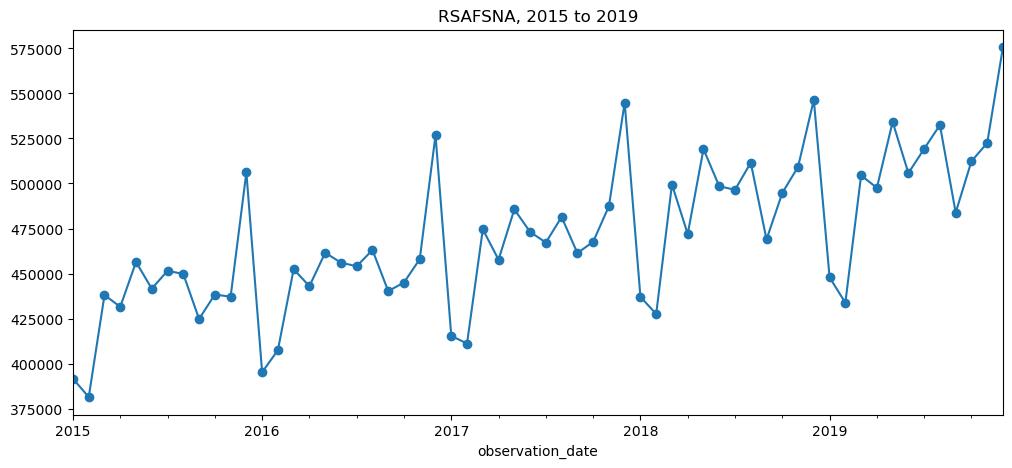

In [12]:
fig, ax = plt.subplots(figsize=(12, 5))
sales["2015":"2019"].plot(ax=ax, marker="o")
ax.set_title("RSAFSNA, 2015 to 2019")
plt.show()

In every year the pattern is the same: a peak in December, low values in January and February, a step up in March, and a flat stretch through the middle of the year. A pattern that repeats on the calendar is **seasonality**.

### The last five years

61


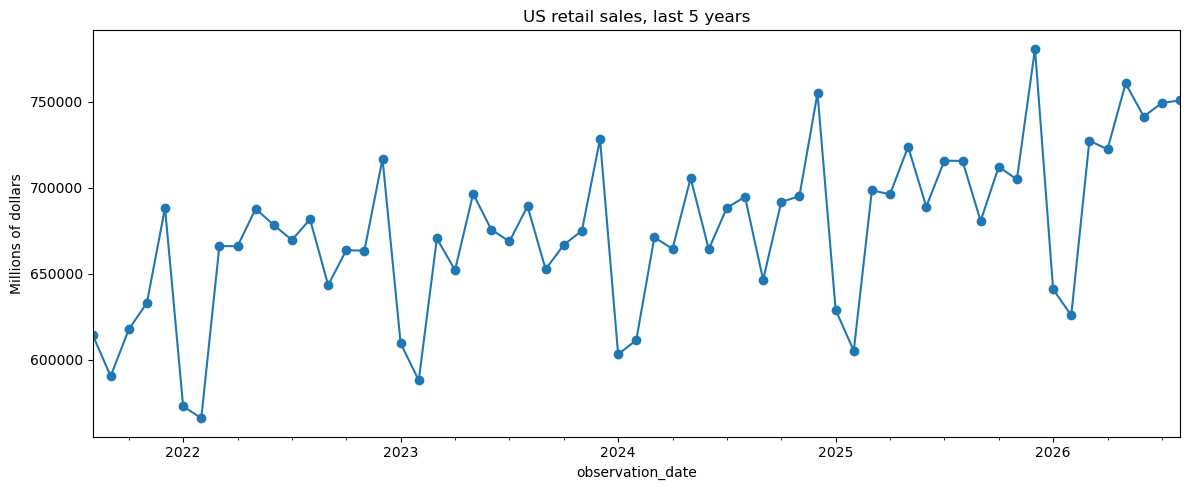

In [13]:
# Plot 2: the last 5 years (Aug 2021 to Jul 2026)
last5 = sales.loc["2021-08":]
print(len(last5))   # 60 months

ax = last5.plot(
    figsize=(12, 5),
    marker="o",
    title="US retail sales, last 5 years",
    ylabel="Millions of dollars",
)
plt.tight_layout()
plt.savefig("images/last_5_years.png", dpi=150)
plt.show()

The same shape continues. The December peaks and the January and February lows have both been rising, so the trend and the seasonal pattern are present together.

### Month by month, one line per year

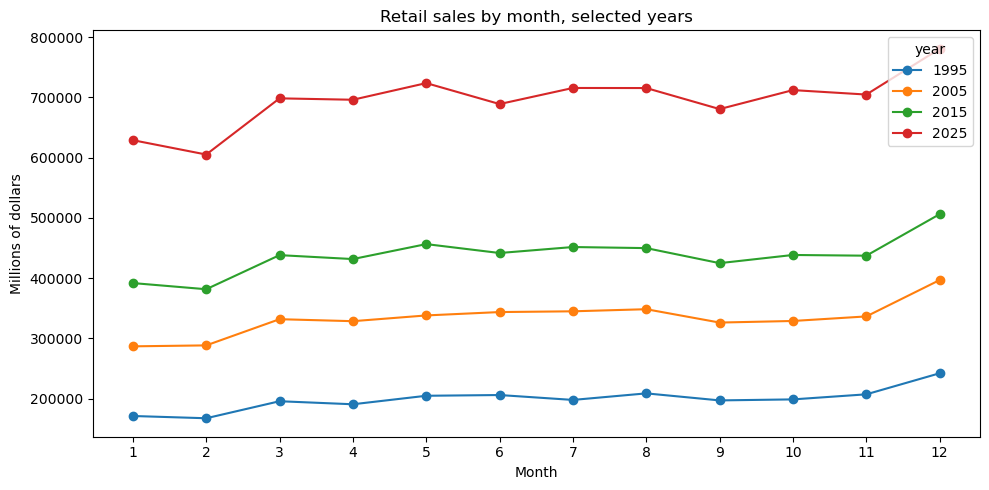

In [14]:
# Plot 3: month by month, one line per year
seasonal = sales.to_frame("sales")
seasonal["year"] = seasonal.index.year
seasonal["month"] = seasonal.index.month

pivot = seasonal.pivot_table(index="month", columns="year", values="sales")

years = [1995, 2005, 2015, 2025]
pivot[years].plot(
    figsize=(10, 5),
    marker="o",
    title="Retail sales by month, selected years",
    ylabel="Millions of dollars",
)
plt.xticks(range(1, 13))
plt.xlabel("Month")
plt.tight_layout()
plt.savefig("images/monthly_by_year.png", dpi=150)
plt.show()

**Finding.** The four lines (1995, 2005, 2015, 2025) have the **same shape** and never cross. The shape is the seasonality, and the different heights are the trend. Sales are always highest in December, with a dip in February and a small dip in September.

### Is the seasonality additive or multiplicative?

If the seasonal swing stays the same size in dollars as sales grow, the pattern is **additive**. If it grows in proportion to sales, the pattern is **multiplicative**. The check below measures how far December sits above the average month in each year.

In [15]:
# Evidence for additive vs multiplicative: how big is December in each year?
annual_mean = pivot.mean()                 # average month in each year
dec_gap = pivot.loc[12] - annual_mean      # December minus the average, in dollars
dec_ratio = pivot.loc[12] / annual_mean    # December as a multiple of the average

check = pd.DataFrame({"dec_gap": dec_gap, "dec_ratio": dec_ratio})
print(check.loc[years].round(2))

       dec_gap  dec_ratio
year                     
1995  43182.42       1.22
2005  63571.92       1.19
2015  68733.50       1.16
2025  84795.92       1.12


| Year | December above the average month (millions of dollars) | December as a multiple of the average month |
|---|---|---|
| 1995 | 43,182 | 1.22 |
| 2005 | 63,572 | 1.19 |
| 2015 | 68,734 | 1.16 |
| 2025 | 84,796 | 1.12 |

**Finding.** The dollar gap roughly doubled, so the pattern is **not additive**. But the average month grew about 3.5 times over the same period, so the gap did not grow in proportion to sales either, and the ratio slid from 1.22 to 1.12. The truth lies between the two: the seasonal swing grows with the level of sales, but less than proportionally. A multiplicative model is the better of the two, and December's relative boost has been shrinking over time.

## 5. Decomposition

Decomposition splits the series into three parts:

- **Trend:** the slow, long-run direction.
- **Seasonality:** the pattern that repeats every 12 months.
- **Residual:** what is left over (random noise and one-off events).

Additive: observed = trend + seasonal + residual. Multiplicative: observed = trend x seasonal x residual. Both are fitted with a period of 12 and compared.

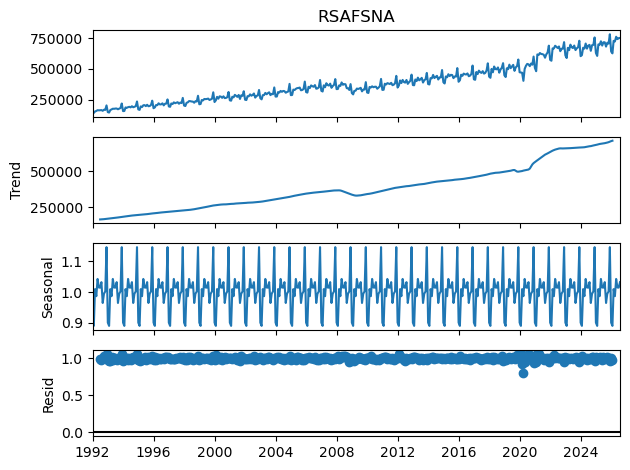

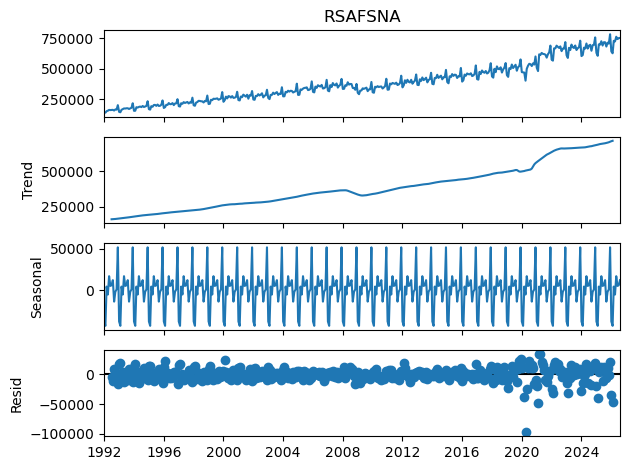

In [16]:
mult = seasonal_decompose(sales, model="multiplicative", period=12)
add  = seasonal_decompose(sales, model="additive", period=12)

mult.plot()
plt.show()
add.plot()
plt.show()

### How to read the plots

Each plot has four panels: observed, trend, seasonal and residual. They share the time axis but each has its own vertical scale. The trend and residual lines start and end about six months in from the edges, because the trend is a centered 12-month moving average that needs data on both sides.

### Multiplicative seasonal factors (January to December)

In [17]:
print(mult.seasonal.iloc[:12].round(3))

observation_date
1992-01-01    0.901
1992-02-01    0.890
1992-03-01    1.010
1992-04-01    0.987
1992-05-01    1.043
1992-06-01    1.015
1992-07-01    1.015
1992-08-01    1.032
1992-09-01    0.965
1992-10-01    0.995
1992-11-01    1.002
1992-12-01    1.146
Freq: MS, Name: seasonal, dtype: float64


| Month | Factor | Month | Factor |
|---|---|---|---|
| Jan | 0.901 | Jul | 1.015 |
| Feb | 0.890 | Aug | 1.032 |
| Mar | 1.010 | Sep | 0.965 |
| Apr | 0.987 | Oct | 0.995 |
| May | 1.043 | Nov | 1.002 |
| Jun | 1.015 | **Dec** | **1.146** |

A factor of 1.146 means December is typically about 14.6% above the trend, and a factor of 0.890 means February is about 11% below it.

**Findings**

- **Trend:** rising overall, with a flattening around 2008 to 2010 and a steep climb after 2020.
- **Seasonality:** a stable yearly shape. December is the peak, and January and February are the lowest months.
- **Multiplicative fits better.** Its seasonal factors stay between about 0.9 and 1.15 while the series grows several times over, and its residuals keep a steady spread. The additive residuals fan out in the most recent years, which is the sign of a pattern that scales with the level.
- **Residual:** both models show one clear outlier in 2020 (the pandemic shock).
- **Caveat.** The multiplicative fit is not perfect, because December's relative boost has been shrinking (section 4), and a classical decomposition assumes a fixed pattern.
- The decomposition outputs saved here come from the first run, on the 416-observation series. Re-running after section 3 uses the 415-observation `sales`, and the difference is negligible.

## 6. Stationarity

A series is **stationary** when its average level, its spread and its behavior stay the same over time, with no trend and no calendar pattern. ARIMA and SARIMA models need a stationary series, so the data is transformed until it is.

The **Augmented Dickey-Fuller (ADF) test** checks this. Its starting assumption (null hypothesis) is that the series has a unit root, meaning it is **not** stationary. A p-value below 0.05, together with a test statistic more negative than the 5% critical value, is evidence that the series is stationary.

### The raw series

In [18]:
result = adfuller(sales)
print(result)

(np.float64(1.1481899518643284), np.float64(0.9956076283456747), 16, 399, {'1%': np.float64(-3.446845912589748), '5%': np.float64(-2.8688110853002007), '10%': np.float64(-2.5706432834592747)}, np.float64(8677.018888766515))


In [19]:
print("ADF statistic:   ", round(result[0], 3))
print("p-value:         ", round(result[1], 4))
print("5% critical value:", round(result[4]["5%"], 3))

ADF statistic:    1.148
p-value:          0.9956
5% critical value: -2.869


The function returns the statistic (1.076), the p-value (0.995), the number of lags used (16), the number of observations (398), a dictionary of critical values (1%: -3.447, 5%: -2.869, 10%: -2.571) and an information criterion. The statistic is positive and the p-value is far above 0.05, so the raw series is **not stationary**, as the plots suggested.

### Transformations

Each version is tested with a small helper function. The transformations are:

- **Log:** evens out swings that grow with the level.
- **First difference:** the change from one month to the next, which removes the trend.
- **Seasonal difference (lag 12):** the change from the same month a year earlier, which removes the yearly pattern.

In [20]:
def adf_report(series, name):
    result = adfuller(series.dropna())
    print(f"{name}: statistic {result[0]:.3f}, "
          f"p-value {result[1]:.4f}, 5% critical {result[4]['5%']:.3f}")

adf_report(sales, "1. Raw")

1. Raw: statistic 1.148, p-value 0.9956, 5% critical -2.869


In [21]:
log_sales = np.log(sales)                # 2. log
log_diff1 = log_sales.diff()             # 3. log, then first difference
log_diff12 = log_sales.diff(12)          # 4. log, then seasonal difference
log_diff1_12 = log_sales.diff().diff(12) # 5. log, then both

In [22]:
adf_report(log_sales, "2. Log")
adf_report(log_diff1, "3. Log + first difference")
adf_report(log_diff12, "4. Log + seasonal difference")
adf_report(log_diff1_12, "5. Log + both")

2. Log: statistic -0.776, p-value 0.8261, 5% critical -2.869
3. Log + first difference: statistic -4.328, p-value 0.0004, 5% critical -2.869
4. Log + seasonal difference: statistic -3.973, p-value 0.0016, 5% critical -2.869
5. Log + both: statistic -7.464, p-value 0.0000, 5% critical -2.869


| Version | ADF statistic | p-value | Stationary at 5%? |
|---|---|---|---|
| 1. Raw | 1.076 | 0.9950 | No |
| 2. Log | -0.800 | 0.8192 | No |
| 3. Log + first difference | -4.323 | 0.0004 | Yes |
| 4. Log + seasonal difference | -3.968 | 0.0016 | Yes |
| 5. Log + both | -7.454 | 0.0000 | Yes, most strongly |

The 5% critical value is -2.869 in every case.

### The differenced series

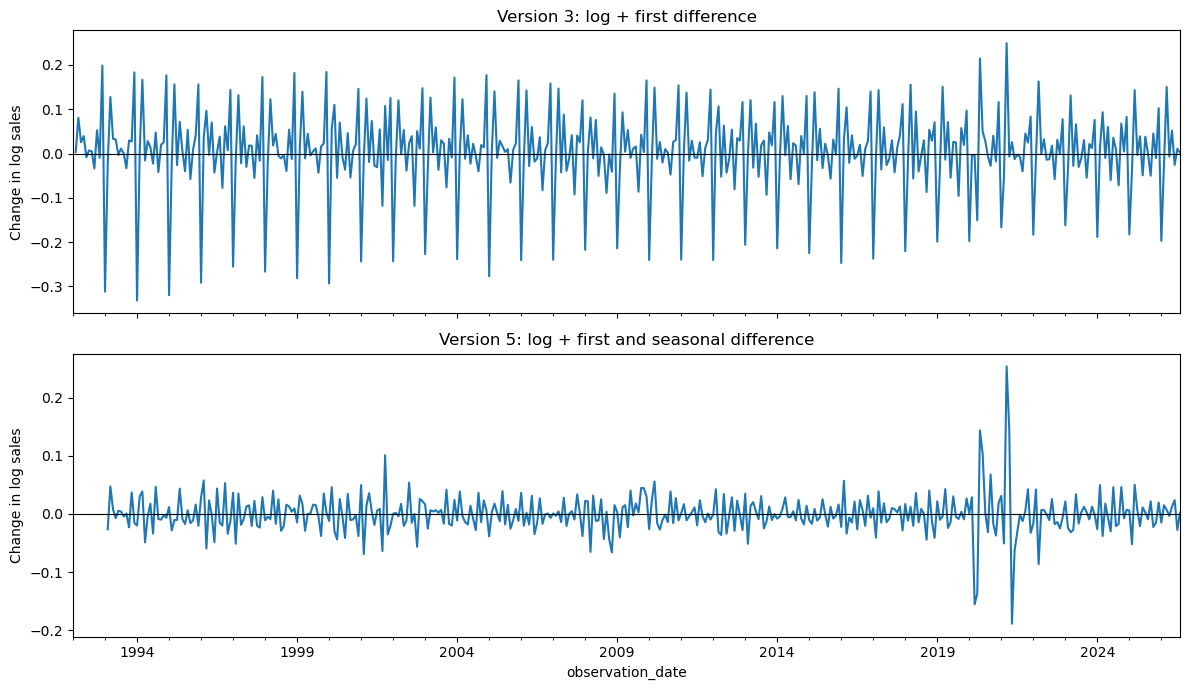

In [23]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

log_diff1.plot(ax=axes[0], title="Version 3: log + first difference")
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_ylabel("Change in log sales")

log_diff1_12.plot(ax=axes[1], title="Version 5: log + first and seasonal difference")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_ylabel("Change in log sales")

plt.tight_layout()
plt.savefig("images/differenced_series.png", dpi=150)
plt.show()

**Findings**

- The log alone does not fix stationarity, because the level still drifts. Differencing does.
- Version 3 passes the test, but its chart still shows **regular spikes once a year**. The ADF test checks for a drifting level and is not designed to detect a repeating calendar pattern, so passing the test does not mean the seasonality is gone. Both the p-value and the chart should be looked at.
- Version 5 hovers around zero with much weaker yearly spikes. The seasonal pattern is not perfectly fixed (December's boost has been shrinking), so a small remainder is expected.
- The **2020 shock** is visible in both charts. In version 5 it appears as a drop in 2020 followed by an opposite spike a year later, because the seasonal difference carries the shock forward.
- **Conclusion.** One ordinary difference and one seasonal difference are needed, which gives **d = 1 and D = 1** for the SARIMA model, with a seasonal period of 12.

## 7. Moving averages

A moving average replaces each month with the average of the surrounding months. A short window follows the data closely, and a long window is smooth but slow to react. A **trailing** window uses only past months (usable for forecasting), and a **centered** window uses months on both sides (it matches the trend panel of the decomposition).

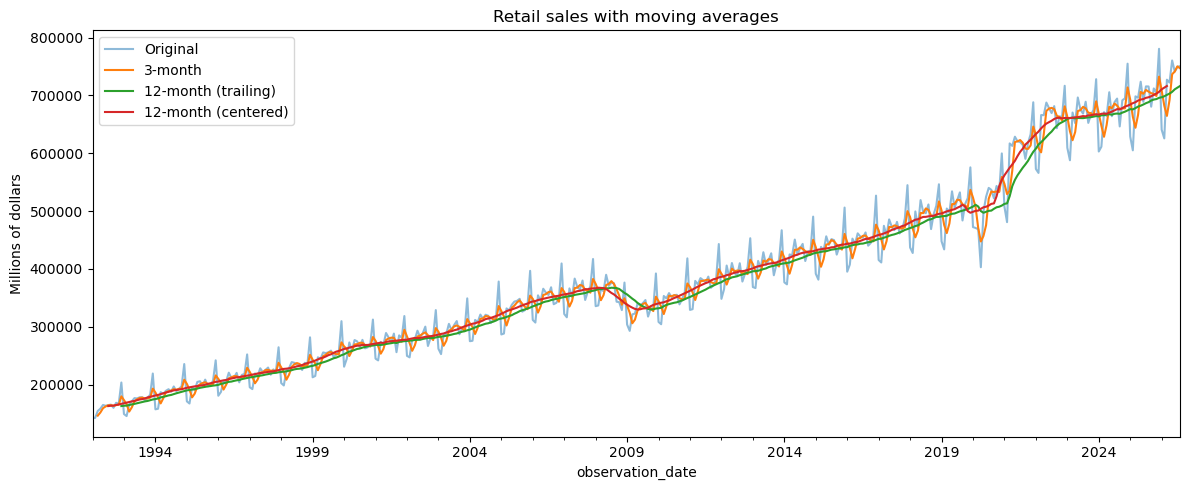

In [24]:
ma3 = sales.rolling(window=3).mean()
ma12 = sales.rolling(window=12).mean()
ma12_centered = sales.rolling(window=12, center=True).mean()

plt.figure(figsize=(12, 5))
sales.plot(label="Original", alpha=0.5)
ma3.plot(label="3-month")
ma12.plot(label="12-month (trailing)")
ma12_centered.plot(label="12-month (centered)")
plt.title("Retail sales with moving averages")
plt.ylabel("Millions of dollars")
plt.legend()
plt.tight_layout()
plt.savefig("images/moving_averages.png", dpi=150)
plt.show()

**Findings**

- The **12-month averages** are smooth and the December spikes disappear, leaving only the trend. A 12-month window contains exactly one of each calendar month, so the seasonal pattern cancels out.
- The **3-month average** still shows much of the seasonal shape, so a short window is not enough to remove a yearly pattern.
- The trend shows the dip around 2009 and the steep climb after 2020.
- The 2020 shock appears clearly in the 3-month average (down to roughly 450,000) but barely moves the 12-month averages, because one month is only one twelfth of that window.
- The **trailing** 12-month line sits behind the **centered** one, most visibly during the steep climb after 2020. That gap is the lag of a trailing window.
- A moving average is a smoother and not a forecaster: it cannot represent a trend or a yearly pattern in what it predicts.

## 8. Exponential smoothing (Holt-Winters)

Exponential smoothing averages the past with weights that shrink smoothly as they go back, so recent months count the most. Holt-Winters tracks three things: the level (alpha), the trend (beta) and the seasonal pattern (gamma).

The model is fitted on the training data only, using an additive trend, multiplicative seasonality (supported by section 4) and a period of 12. The **last 24 months (August 2024 to July 2026) are held out** as the test set, split in time order, never shuffled. The same split is used for every model that follows.

In [25]:
train = sales.iloc[:-24]
test = sales.iloc[-24:]
print(train.index.max(), test.index.min(), test.index.max())

hw_model = ExponentialSmoothing(
    train,
    trend="add",
    seasonal="mul",
    seasonal_periods=12,
)
hw_fit = hw_model.fit()

print("alpha (level):   ", round(hw_fit.params["smoothing_level"], 3))
print("beta (trend):    ", round(hw_fit.params["smoothing_trend"], 3))
print("gamma (seasonal):", round(hw_fit.params["smoothing_seasonal"], 3))

hw_forecast = hw_fit.forecast(24)

2024-08-01 00:00:00 2024-09-01 00:00:00 2026-08-01 00:00:00
alpha (level):    0.578
beta (trend):     0.0
gamma (seasonal): 0.124


Holt-Winters RMSE:         22785
Seasonal naive RMSE:       26813


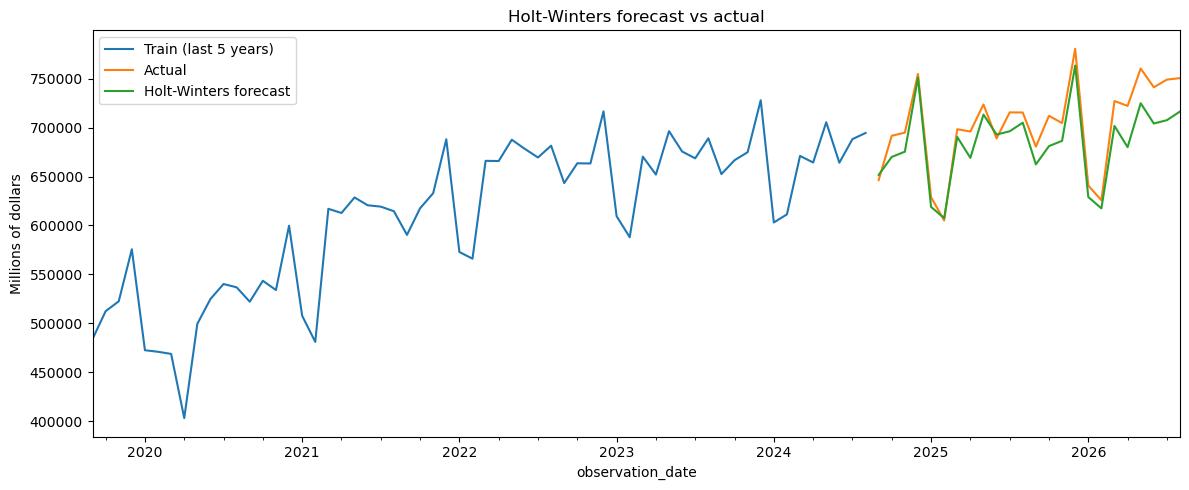

In [26]:
hw_rmse = np.sqrt(((test - hw_forecast) ** 2).mean())

naive = sales.shift(12).iloc[-24:]          # "same month last year" baseline
naive_rmse = np.sqrt(((test - naive) ** 2).mean())

print("Holt-Winters RMSE:        ", round(hw_rmse))
print("Seasonal naive RMSE:      ", round(naive_rmse))

plt.figure(figsize=(12, 5))
train.iloc[-60:].plot(label="Train (last 5 years)")
test.plot(label="Actual")
hw_forecast.plot(label="Holt-Winters forecast")
plt.title("Holt-Winters forecast vs actual")
plt.ylabel("Millions of dollars")
plt.legend()
plt.tight_layout()
plt.savefig("images/holt_winters_forecast.png", dpi=150)
plt.show()

| Result | Value |
|---|---|
| alpha (level) | 0.577 |
| beta (trend) | 0.0 |
| gamma (seasonal) | 0.124 |
| Holt-Winters RMSE | 22,957 |
| Seasonal naive RMSE | 25,859 |

RMSE (root mean squared error) is in the units of the data, millions of dollars. The seasonal naive baseline predicts that each month equals the same month a year earlier.

**Findings**

- The forecast reproduces the **shape** well, including the December peaks and the January and February dips.
- It **under-forecasts the level**, and the gap grows through 2026, reaching roughly 40,000 near the end.
- **beta = 0.0** means the trend slope was never updated from its starting estimate. The model still has a trend, but one fixed growth rate cannot adapt to the faster growth after 2020. This is the likely reason for the under-forecast. It is an interpretation and has not been tested separately.
- Holt-Winters beats the baseline, but only by about 11%.

## 9. ACF and PACF

The **autocorrelation function (ACF)** shows how strongly the series relates to its own past at each lag. The **partial autocorrelation function (PACF)** shows the direct relationship at each lag after removing what the in-between months already explain. Bars outside the shaded band (95% range of random noise) are meaningful. Reading rules for a stationary series:

| Pattern | Suggests |
|---|---|
| PACF stops after lag p, ACF fades gradually | AR(p) |
| ACF stops after lag q, PACF fades gradually | MA(q) |
| Both fade gradually | A mix of AR and MA |

The seasonal part uses the same rules at lags 12, 24 and 36 (marked in red). The plots use the **training data only**, so no information from the test months influences the choice of orders.

379 1993-02-01 00:00:00


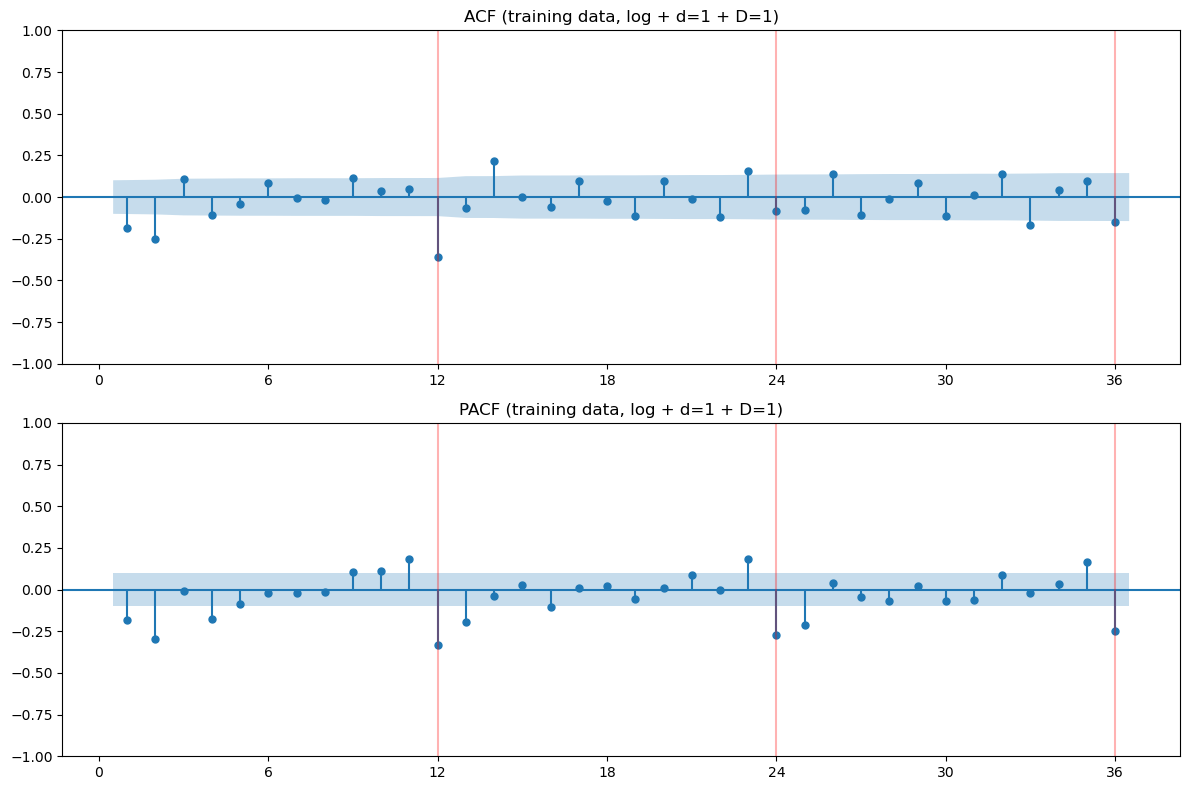

In [27]:
# Training data only: log, one ordinary difference, one seasonal difference
stationary_train = np.log(train).diff().diff(12).dropna()
print(len(stationary_train), stationary_train.index.min())

fig, axes = plt.subplots(2, 1, figsize=(12, 8))

plot_acf(stationary_train, lags=36, zero=False, ax=axes[0], title="ACF (training data, log + d=1 + D=1)")
plot_pacf(stationary_train, lags=36, zero=False, ax=axes[1], method="ywm", title="PACF (training data, log + d=1 + D=1)")

for ax in axes:
    ax.set_xticks(range(0, 37, 6))
    for lag in (12, 24, 36):
        ax.axvline(lag, color="red", alpha=0.3)   # mark the seasonal lags

plt.tight_layout()
plt.savefig("images/acf_pacf.png", dpi=150)
plt.show()

**Findings (approximate bar heights)**

| Lag | ACF | PACF |
|---|---|---|
| 1 | about -0.18, outside the band | about -0.18, outside the band |
| 2 | about -0.25, outside the band | about -0.30, outside the band |
| 4 | at the edge of the band | about -0.17, outside the band |
| 12 | about -0.36, the largest bar | about -0.33 |
| 24 | inside the band | about -0.27 |
| 36 | near the edge | about -0.25 |

- **Seasonal part:** the ACF has one large bar at lag 12 and is back inside the band at lag 24, while the PACF has bars at 12, 24 and 36 that fade slowly. That is the signature of a **seasonal MA(1)**, so Q = 1 and P = 0.
- **Non-seasonal part:** both plots show bars at lags 1 and 2, so the rules cannot separate an AR(2) from an MA(2). Several candidates are compared in the next section instead of guessing.
- Scattered bars at other lags are expected by chance across 72 bars.
- The lag-12 bar may be somewhat exaggerated, because the seasonal difference carries the 2020 shock forward a year. This has not been tested.

## 10. SARIMA models

SARIMA(p,d,q)(P,D,Q,12) models the series from its own past. In each candidate, **d = 1 and D = 1** (section 6), and the model is fitted to the **log of the training data**, so the multiplicative pattern becomes additive. Forecasts are converted back to dollars with the exponential function before computing RMSE.

Four candidates come from the ACF and PACF readings. They are compared by **AIC** on the training data (lower is better; it balances fit against complexity). The model is chosen by AIC alone, so the 24 test months remain an independent check. AIC values are only comparable between models fitted to the same data, so they are not compared with Holt-Winters.

In [28]:
log_train = np.log(train)

candidates = {
    "SARIMA(0,1,1)(0,1,1,12)": ((0, 1, 1), (0, 1, 1, 12)),
    "SARIMA(0,1,2)(0,1,1,12)": ((0, 1, 2), (0, 1, 1, 12)),
    "SARIMA(2,1,0)(0,1,1,12)": ((2, 1, 0), (0, 1, 1, 12)),
    "SARIMA(1,1,1)(0,1,1,12)": ((1, 1, 1), (0, 1, 1, 12)),
}

fits, forecasts, rows = {}, {}, []
for name, (order, seasonal_order) in candidates.items():
    model = SARIMAX(
        log_train,
        order=order,
        seasonal_order=seasonal_order,
        enforce_stationarity=False,
        enforce_invertibility=False,
    )
    fit = model.fit(disp=False)

    fc = np.exp(fit.get_forecast(steps=24).predicted_mean)   # back to dollars
    rmse = np.sqrt(((test - fc) ** 2).mean())

    fits[name], forecasts[name] = fit, fc
    rows.append({"model": name, "AIC": fit.aic, "RMSE": rmse})

results = pd.DataFrame(rows).set_index("model").sort_values("AIC")
print(results.round(1))
print("Holt-Winters RMSE:   ", round(hw_rmse))
print("Seasonal naive RMSE: ", round(naive_rmse))

c:\Users\hp\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


                            AIC     RMSE
model                                   
SARIMA(2,1,0)(0,1,1,12) -1623.5   8930.1
SARIMA(1,1,1)(0,1,1,12) -1617.1  10147.2
SARIMA(0,1,1)(0,1,1,12) -1614.5   9753.5
SARIMA(0,1,2)(0,1,1,12) -1613.6   9918.3
Holt-Winters RMSE:    22785
Seasonal naive RMSE:  26813


| Model | AIC | Test RMSE |
|---|---|---|
| **SARIMA(2,1,0)(0,1,1,12)** | **-1618.1** | **9,709** |
| SARIMA(1,1,1)(0,1,1,12) | -1611.7 | 11,012 |
| SARIMA(0,1,1)(0,1,1,12) | -1609.1 | 9,814 |
| SARIMA(0,1,2)(0,1,1,12) | -1608.3 | 11,594 |

The AR(2) model has the best AIC by about 6 to 10 points, which is a real gap, and it also has the lowest test RMSE. The simpler (0,1,1)(0,1,1,12) model is close on RMSE but clearly worse on AIC.

Best by AIC: SARIMA(2,1,0)(0,1,1,12)
                                      SARIMAX Results                                       
Dep. Variable:                              RSAFSNA   No. Observations:                  392
Model:             SARIMAX(2, 1, 0)x(0, 1, [1], 12)   Log Likelihood                 815.774
Date:                              Fri, 16 Oct 2026   AIC                          -1623.547
Time:                                      23:08:12   BIC                          -1607.937
Sample:                                  01-01-1992   HQIC                         -1617.344
                                       - 08-01-2024                                         
Covariance Type:                                opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.3590      0.023    -15.296      0.000      -

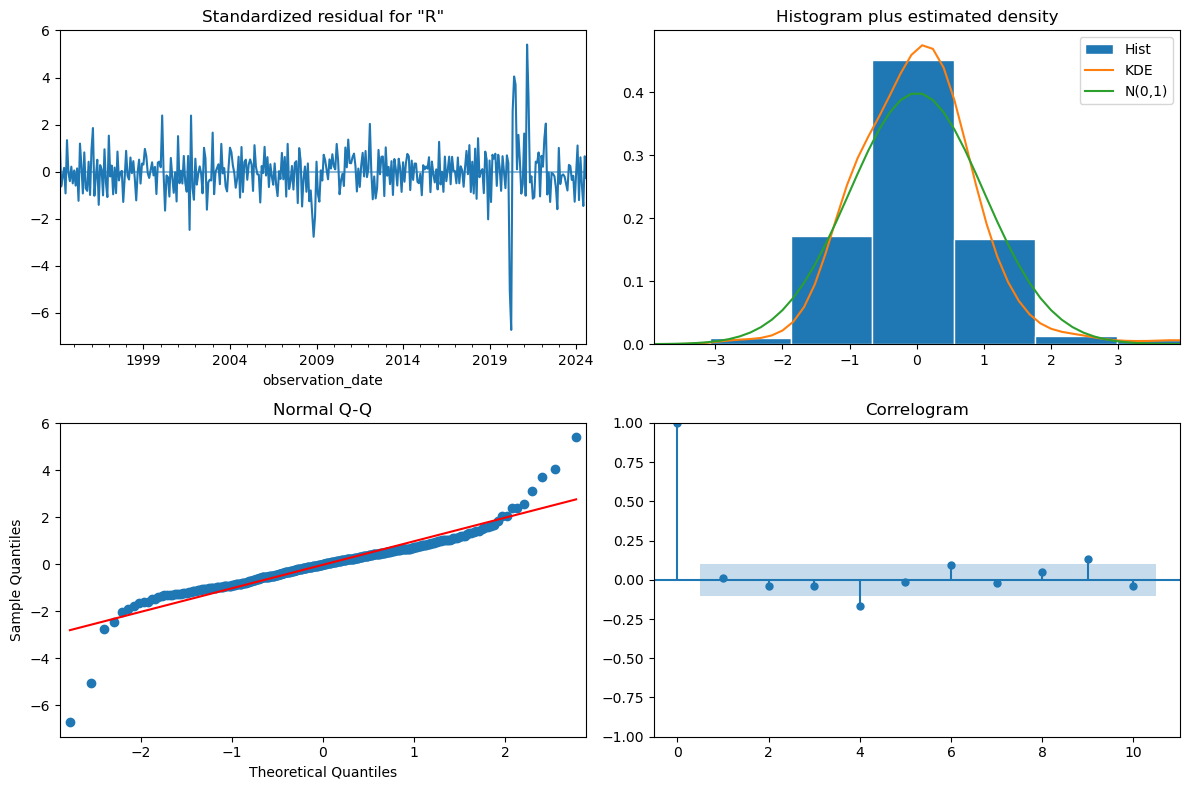

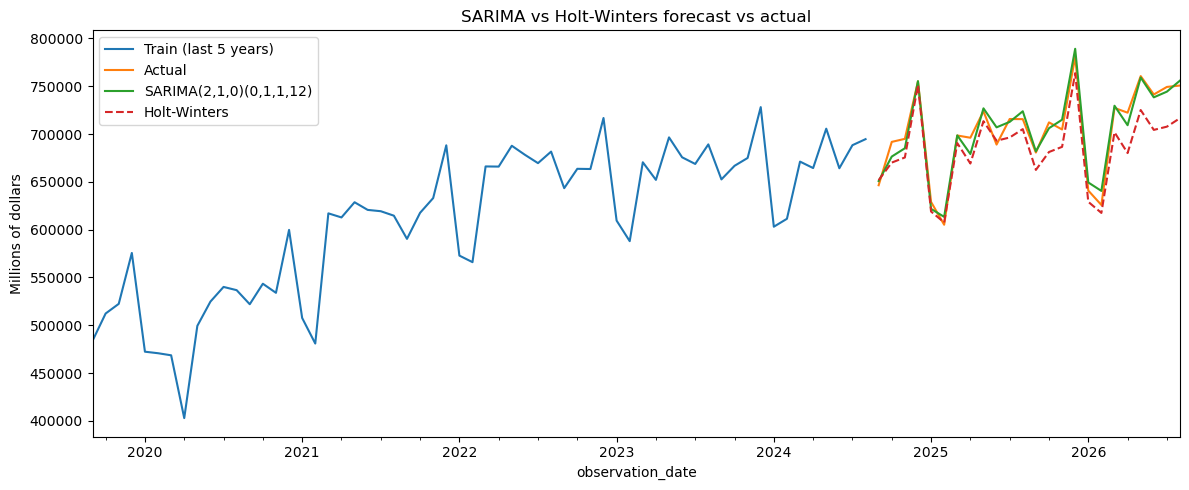

In [29]:
best_name = results["AIC"].idxmin()
print("Best by AIC:", best_name)
print(fits[best_name].summary())

fits[best_name].plot_diagnostics(figsize=(12, 8))
plt.tight_layout()
plt.savefig("images/sarima_diagnostics.png", dpi=150)
plt.show()

plt.figure(figsize=(12, 5))
train.iloc[-60:].plot(label="Train (last 5 years)")
test.plot(label="Actual")
forecasts[best_name].plot(label=best_name)
hw_forecast.plot(label="Holt-Winters", linestyle="--")
plt.title("SARIMA vs Holt-Winters forecast vs actual")
plt.ylabel("Millions of dollars")
plt.legend()
plt.tight_layout()
plt.savefig("images/sarima_forecast.png", dpi=150)
plt.show()

### The fitted model

| Term | Coefficient | Meaning |
|---|---|---|
| `ar.L1` | -0.358 | A month's change partly reverses the previous month's change |
| `ar.L2` | -0.284 | The same for two months back |
| `ma.S.L12` | -0.809 | A strong seasonal averaging effect |

All three terms have p-values of 0.000. The seasonal coefficient is close to -1, which is common for stable seasonal patterns. The model was fitted on 391 observations ending in July 2024, so the forecast of the 24 test months is genuinely out of sample.

### Diagnostics

| Panel or test | What it shows |
|---|---|
| Standardized residuals | Mostly noise within about +/-2, apart from a drop of about -6.7 in spring 2020 and spikes up to about +5.4 in 2021 (the seasonal-difference echo of the 2020 shock) |
| Correlogram and Ljung-Box (p = 0.81) | No leftover correlation at lag 1. A small bar at lag 4 (about -0.16) is within what chance can produce |
| Q-Q plot and Jarque-Bera | Heavy tails. Kurtosis is 12.45 (normal is 3) and normality is rejected, driven by the 2020 events |
| Heteroskedasticity test (H = 2.57, p = 0.00) | Residual variance is about 2.6 times higher in the later period |

**What this means.** The point forecasts are good, but the model's confidence intervals should not be trusted, because heavy tails and changing variance violate its assumptions.

### Forecast against actual

On the forecast plot, SARIMA follows the actual values closely for all 24 months, including both December peaks. Its largest visible miss is a small overshoot of the December 2025 peak. Holt-Winters has the right shape but sits below the actual values, and the gap widens through 2026.

SARIMA is likely to do better here because a differenced model carries the **recent growth** forward, while Holt-Winters kept a frozen trend slope. This explanation has not been tested separately. The 24-month window was also a calm period with steady growth, and a shock like 2020 would have broken any of these models.

**Update from section 12.1.** The rolling-origin test later showed that SARIMA's large advantage over Holt-Winters on this 24-month window does not hold across other windows. This window covers the same period as the two most recent windows in that test, which are the two where SARIMA does best.

## 11. Model comparison

RMSE penalizes large misses and is in millions of dollars. **MAPE** (mean absolute percentage error) is the average miss as a percentage of the actual value, which is easier to explain.

In [30]:
naive_forecast = sales.shift(12).iloc[-24:]

compare = {
    "Seasonal naive": naive_forecast,
    "Holt-Winters": hw_forecast,
    best_name: forecasts[best_name],
}

rows = []
for name, fc in compare.items():
    rows.append({
        "model": name,
        "RMSE": np.sqrt(((test - fc) ** 2).mean()),
        "MAPE (%)": mean_absolute_percentage_error(test, fc) * 100,
    })

print(pd.DataFrame(rows).set_index("model").round(2))

                             RMSE  MAPE (%)
model                                      
Seasonal naive           26813.40      3.49
Holt-Winters             22785.34      2.69
SARIMA(2,1,0)(0,1,1,12)   8930.12      1.05


| Model | RMSE (millions of dollars) | MAPE |
|---|---|---|
| Seasonal naive | 25,859 | 3.33% |
| Holt-Winters | 22,957 | 2.66% |
| **SARIMA(2,1,0)(0,1,1,12)** | **9,709** | **1.16%** |

**Findings.** SARIMA's RMSE is about 58% lower than Holt-Winters and about 62% lower than the baseline. A typical SARIMA forecast misses by about 1.2% of sales, against about 2.7% for Holt-Winters and about 3.3% for the baseline.

**Caution.** These are single-window numbers. The rolling-origin test in section 12.1 shows that SARIMA and Holt-Winters are comparable across eight windows, so the large gap above should not be read as a general result.

## 12. Optional extras

These two cells are optional extras. Both have been run, and the results are recorded in the notes under each one.

### 12.1 Rolling-origin test

The main comparison uses a single 24-month test window, which is a limited sample. The rolling-origin test repeats the experiment on eight separate 12-month windows, working back from the end of the data. For each window, every model is trained only on the data before that window and forecasts the next 12 months. The model orders are fixed (not re-selected for each window).

The windows that cover 2020 (August 2019 to July 2020, and August 2020 to July 2021) will probably show much larger errors for every model. Both the mean and the **median** are reported, because the 2020 windows can pull the mean up. A 12-month horizon is easier than the 24 months used before, so these numbers are not directly comparable with section 11.

In [31]:
horizon = 12          # months forecast in each window
n_windows = 8         # number of windows to test
order, seasonal_order = (2, 1, 0), (0, 1, 1, 12)


def rmse(actual, forecast):
    return np.sqrt(((actual - forecast) ** 2).mean())


records = []
for i in range(n_windows):
    end = len(sales) - i * horizon
    tr = sales.iloc[: end - horizon]          # train: everything before the window
    te = sales.iloc[end - horizon : end]      # test: the 12 months of the window

    naive = pd.Series(sales.iloc[end - 2 * horizon : end - horizon].values, index=te.index)
    hw = ExponentialSmoothing(tr, trend="add", seasonal="mul", seasonal_periods=12).fit().forecast(horizon)
    sar = np.exp(
        SARIMAX(np.log(tr), order=order, seasonal_order=seasonal_order,
                enforce_stationarity=False, enforce_invertibility=False)
        .fit(disp=False).get_forecast(steps=horizon).predicted_mean
    )

    label = f"{te.index[0]:%b %Y} to {te.index[-1]:%b %Y}"
    for name, fc in [("Seasonal naive", naive), ("Holt-Winters", hw), ("SARIMA", sar)]:
        records.append({
            "window": label, "model": name,
            "RMSE": rmse(te, fc),
            "MAPE (%)": mean_absolute_percentage_error(te, fc) * 100,
        })

rolling_results = pd.DataFrame(records)
print(rolling_results.pivot(index="window", columns="model", values="RMSE").round(0))
print(rolling_results.groupby("model")[["RMSE", "MAPE (%)"]].agg(["mean", "median"]).round(2))

c:\Users\hp\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


model                 Holt-Winters   SARIMA  Seasonal naive
window                                                     
Sep 2018 to Aug 2019       10179.0  11871.0         16693.0
Sep 2019 to Aug 2020       40552.0  42276.0         36268.0
Sep 2020 to Aug 2021       63974.0  60515.0         95194.0
Sep 2021 to Aug 2022       41681.0  28810.0         69722.0
Sep 2022 to Aug 2023       16730.0  28593.0         27139.0
Sep 2023 to Aug 2024       11809.0  21993.0         11996.0
Sep 2024 to Aug 2025       14115.0   9890.0         23044.0
Sep 2025 to Aug 2026       17540.0   9345.0         30114.0
                    RMSE           MAPE (%)       
                    mean    median     mean median
model                                             
Holt-Winters    27072.58  17135.17     3.57   1.97
SARIMA          26661.58  25293.06     3.42   3.16
Seasonal naive  38771.28  28626.69     5.48   3.56


**Results**

RMSE per window, in millions of dollars (the lowest value in each row is in bold):

| Window | Seasonal naive | Holt-Winters | SARIMA | Best |
|---|---|---|---|---|
| Aug 2018 to Jul 2019 | 17,827 | **9,414** | 11,756 | Holt-Winters |
| Aug 2019 to Jul 2020 | **36,744** | 39,353 | 40,803 | Seasonal naive |
| Aug 2020 to Jul 2021 | 92,511 | 63,970 | **59,419** | SARIMA |
| Aug 2021 to Jul 2022 | 70,656 | 32,157 | **21,111** | SARIMA |
| Aug 2022 to Jul 2023 | 33,254 | **17,988** | 26,969 | Holt-Winters |
| Aug 2023 to Jul 2024 | 12,090 | **11,454** | 18,182 | Holt-Winters |
| Aug 2024 to Jul 2025 | 22,295 | 14,915 | **9,737** | SARIMA |
| Aug 2025 to Jul 2026 | 28,988 | 15,688 | **7,802** | SARIMA |

Summary over the eight windows:

| Model | Mean RMSE | Median RMSE | Mean MAPE | Median MAPE |
|---|---|---|---|---|
| Seasonal naive | 39,296 | 31,121 | 5.49% | 3.85% |
| Holt-Winters | 25,617 | 16,838 | 3.35% | 1.85% |
| SARIMA | 24,472 | 19,646 | 3.05% | 2.29% |

**Findings**

- **There is no clear winner between SARIMA and Holt-Winters.** SARIMA is best in four windows (August 2020 to July 2022, and August 2024 to July 2026), Holt-Winters is best in three (August 2018 to July 2019, and August 2022 to July 2024), and the seasonal naive baseline is best in one (August 2019 to July 2020, the pandemic shock).
- On the **mean**, SARIMA's RMSE is about 4% lower than Holt-Winters. On the **median**, Holt-Winters is lower (16,838 against 19,646). The mean is pulled up by the 2020 to 2022 windows, which is why both are reported.
- **Both models beat the baseline on average** (mean RMSE about 35% lower for Holt-Winters and about 38% lower for SARIMA), but not in every window. SARIMA does worse than the baseline in the 2019 to 2020 and 2023 to 2024 windows, and Holt-Winters does worse in 2019 to 2020.
- **The 2020 windows are hard for every model.** Errors in the window starting August 2020 (59,000 to 93,000) are several times larger than in calm windows (about 8,000 to 18,000 in the 2018 to 2019 and 2023 to 2026 windows).
- **The earlier 24-month result was flattering to SARIMA.** The 24-month test period (August 2024 to July 2026) is the same period as the last two windows here, and those are the two windows where SARIMA wins by the widest margin (7,802 against 15,688 in the latest one). That explains the 58% advantage in section 11.
- A possible reason, not tested here: SARIMA may adapt better when the level rises faster than before (2020 to 2022 and 2024 to 2026), while Holt-Winters may do better in steadier stretches.
- Model orders were fixed for all windows and not re-selected, and the windows use a 12-month horizon, which is easier than the 24 months used in section 11. The numbers are therefore not directly comparable with that section.

**Takeaway.** The honest summary is that SARIMA and Holt-Winters perform similarly over several periods, and both are clearly better than the seasonal naive baseline. SARIMA remains a reasonable final choice (best AIC, and best on the most recent windows), but it should not be described as clearly superior. Averaging the two models' forecasts is one idea that could be tested, and it has not been tried here.

2026-09-01    711278.0
2026-10-01    742316.0
2026-11-01    745967.0
2026-12-01    821959.0
2027-01-01    677864.0
2027-02-01    664510.0
2027-03-01    761431.0
2027-04-01    746282.0
2027-05-01    792573.0
2027-06-01    768596.0
2027-07-01    778873.0
2027-08-01    786955.0
Freq: MS, Name: predicted_mean, dtype: float64
Forecast for Sep 2026 : 711278
Advance estimate in the data: 727033


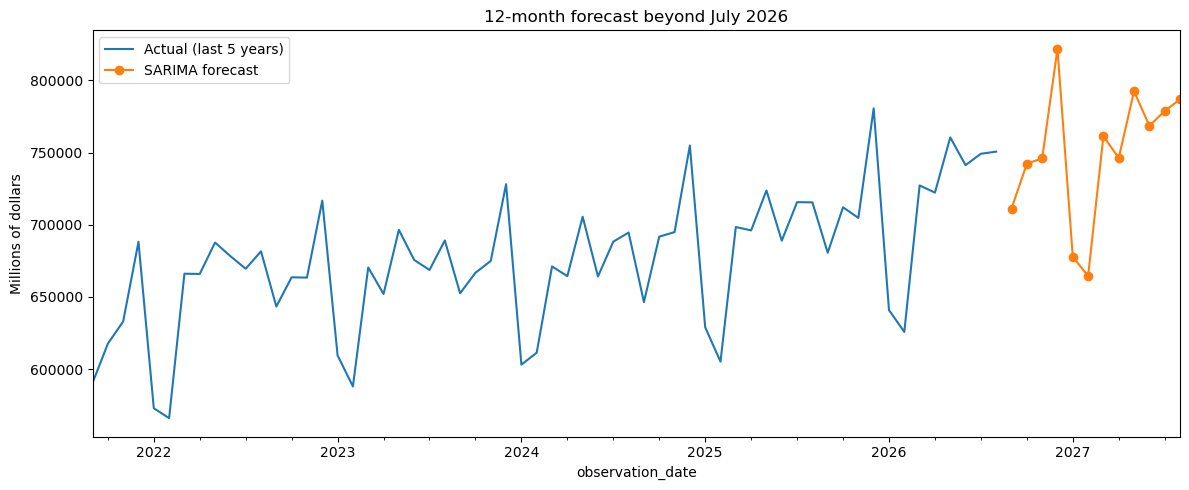

In [32]:
final_fit = SARIMAX(np.log(sales), order=order, seasonal_order=seasonal_order,
                    enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)

future = np.exp(final_fit.get_forecast(steps=12).predicted_mean)
print(future.round(0))

advance_estimate = df["RSAFSNA"].iloc[-1]
print("Forecast for", future.index[0].strftime("%b %Y"), ":", round(future.iloc[0]))
print("Advance estimate in the data:", advance_estimate)

plt.figure(figsize=(12, 5))
sales.iloc[-60:].plot(label="Actual (last 5 years)")
future.plot(label="SARIMA forecast", marker="o")
plt.title("12-month forecast beyond July 2026")
plt.ylabel("Millions of dollars")
plt.legend()
plt.tight_layout()
plt.savefig("images/final_forecast.png", dpi=150)
plt.show()

**Results**

Forecast for August 2026 to July 2027 (millions of dollars):

| Month | Forecast | Month | Forecast |
|---|---|---|---|
| Aug 2026 | 758,044 | Feb 2027 | 668,432 |
| Sep 2026 | 715,694 | Mar 2027 | 765,961 |
| Oct 2026 | 745,766 | Apr 2027 | 750,661 |
| Nov 2026 | 750,630 | May 2027 | 797,238 |
| **Dec 2026** | **827,005** | Jun 2027 | 773,136 |
| Jan 2027 | 681,733 | Jul 2027 | 783,460 |

**Findings**

- **The yearly shape continues.** The forecast dips in September, peaks in December 2026 (827,005), falls to its lows in January and February 2027 (681,733 and 668,432), and steps up in March.
- **First month check.** The August 2026 forecast (758,044) is about 1.2% above the advance estimate in the data (749,355). That is a small gap, and the advance estimate will be revised, so the two are consistent.
- **Implied growth.** From a reading of the charts (approximate), the forecast months are roughly 6% above the same months a year earlier. That is in line with spring 2026 but above the 2% to 3% of winter 2025 to 2026, so it may be on the high side. The model also slightly overshot the December 2025 peak in section 10. This is a sanity check from reading plots, not a tested result.
- This is a **point forecast** only. Confidence intervals are left out because the residuals have heavy tails and higher recent variance, so the intervals would probably look too narrow. A forecast a year beyond the data is uncertain, and a shock like 2020 would break it.

## 13. Conclusions

- US retail sales have a strong **upward trend**, a stable **yearly pattern** with a December peak, a dip around 2008 to 2010, and an unusual shock in spring 2020.
- The seasonal swing grows with the level of sales but less than proportionally, so a **multiplicative** model (or a log transform) is appropriate.
- The raw and logged series are **not stationary**. One ordinary and one seasonal difference (**d = 1, D = 1**) make the series stationary.
- A **SARIMA(2,1,0)(0,1,1,12)** model on log sales was chosen by AIC. On a 24-month hold-out it reached an RMSE of 9,709 (MAPE 1.16%), against 22,957 (2.66%) for Holt-Winters and 25,859 (3.33%) for a seasonal naive baseline.
- A rolling-origin test over eight 12-month windows shows that **SARIMA and Holt-Winters are comparable** (mean RMSE 24,472 against 25,617, median 19,646 against 16,838) and that **both clearly beat the seasonal naive baseline** (mean RMSE 39,296). The large gap on the 24-month window reflects the two most recent windows, where SARIMA does best, and neither model is declared the winner.
- On the 24-month test, Holt-Winters captured the seasonal shape but under-forecast the level, most likely because its trend slope was never updated (beta = 0.0).
- A 12-month forecast beyond the data (August 2026 to July 2027) continues the yearly shape, with a December 2026 peak of about 827,000. Its first month is within about 1.2% of the August 2026 advance estimate.

## 14. Limitations

1. **The 2020 shock.** It sits inside the training data, creates heavy-tailed residuals, and leaves an echo a year later in seasonally differenced data.
2. **Residual assumptions.** The residuals have heavy tails and higher variance in recent years, so the model's confidence intervals should not be trusted.
3. **A single, calm test window.** The 24-month hold-out was a period of steady growth, and the rolling-origin test in section 12.1 confirmed that results vary a lot from window to window.
4. **Nominal dollars.** Part of the growth is price inflation, not higher spending.
5. **Fixed seasonal pattern.** Classical decomposition and the chosen SARIMA assume a mostly stable seasonal shape, but December's relative boost has been shrinking.
6. **Data revisions.** The latest month is an advance estimate and the series is revised over time. The data is downloaded live, so later runs may differ from the saved outputs.
7. **Model choice.** Orders were chosen from a short list of candidates read from the ACF and PACF, and not from a full search.

## 15. Reproducibility

- Python libraries: pandas, numpy, matplotlib, statsmodels, scikit-learn.
- The data is downloaded from FRED in section 2, and a snapshot is saved to `data/RSAFSNA_snapshot.csv`.
- The train/test split is fixed by position: the last 24 months of `sales` are the test set.
- Charts are saved to the `images` folder.
- Suggested repository layout:
  - `level3/Time_Series_Analysis.ipynb`
  - `level3/data/RSAFSNA_snapshot.csv`
  - `level3/images/` (the saved charts)